## Imports

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import kagglehub
import scipy.stats as stats

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, classification_report
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight

from lightgbm import LGBMClassifier


/home/orlandojunior/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Download latest version
path = kagglehub.competition_download('playground-series-s6e10')

print("Path to competition files:", path)

Path to competition files: /home/orlandojunior/.cache/kagglehub/competitions/playground-series-s6e10


## Leitura dos dados

In [3]:
df_train  = pd.read_csv(f'{path}/train.csv')
df_test  = pd.read_csv(f'{path}/test.csv')

In [4]:
def make_mi_scores(X, y, discrete_features):
    mi_scores = mutual_info_regression(X, y, discrete_features=discrete_features)
    mi_scores = pd.Series(mi_scores, name="MI Scores", index=X.columns)
    mi_scores = mi_scores.sort_values(ascending=False)
    return mi_scores

def plot_mi_scores(scores):
    scores = scores.sort_values(ascending=True)
    width = np.arange(len(scores))
    ticks = list(scores.index)
    plt.barh(width, scores)
    plt.yticks(width, ticks)
    plt.title("Mutual Information Scores")

In [5]:
pipeline = Pipeline(
    steps=[
        ('imputer',SimpleImputer(missing_values=np.nan, strategy='mean'))
    ]
)
numeric_features = df_train.select_dtypes(include=['number']).columns
df_train[numeric_features] = pipeline.fit_transform(df_train[numeric_features])

In [6]:
df_train.isna().sum()

id                                   0
Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64

In [7]:
# X = df_train.copy()
# y = X.pop("satisfaction")

# for colname in X.select_dtypes("object"):
#     X[colname], _ = X[colname].factorize()

# discrete_features = X.dtypes == int

In [8]:
# mi_scores = make_mi_scores(X, y, discrete_features)
# mi_scores[::3] 

In [9]:
# plt.figure(dpi=100, figsize=(8, 5))
# plot_mi_scores(mi_scores)

In [10]:
df_train['Inflight wifi service'].head()

0    4.0
1    5.0
2    3.0
3    3.0
4    3.0
Name: Inflight wifi service, dtype: float64

In [11]:
def feature_engineering(df_train: pd.DataFrame, df_test: pd.DataFrame):
    ids = df_test['id']

    df_test = df_test.drop(columns=['id'])
    df_train = df_train.drop(columns=['id'])

    df = pd.concat([df_train,df_test],axis=0)
   
    df['satisfaction'] = df['satisfaction'].apply(lambda x: 1 if x == True else 0)
    df['inflight_service'] = (df['Inflight wifi service'] + df['Inflight entertainment'])/2

    
    return df, ids
    
    
    

In [12]:
df, ids = feature_engineering(df_train, df_test)

In [13]:
df.info()

<class 'pandas.DataFrame'>
Index: 999479 entries, 0 to 299843
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Age                                999479 non-null  float64
 1   Flight Distance                    999479 non-null  float64
 2   Inflight wifi service              999479 non-null  float64
 3   Departure/Arrival time convenient  999479 non-null  float64
 4   Ease of Online booking             999479 non-null  float64
 5   Gate location                      999479 non-null  float64
 6   Food and drink                     999479 non-null  float64
 7   Online boarding                    999479 non-null  float64
 8   Seat comfort                       999479 non-null  float64
 9   Inflight entertainment             999479 non-null  float64
 10  On-board service                   999479 non-null  float64
 11  Leg room service                   999479 non-null  flo

In [14]:
features_numericas = df.select_dtypes(include=['number']).columns
features_categoricas = df.select_dtypes(include=['str']).columns

<Axes: >

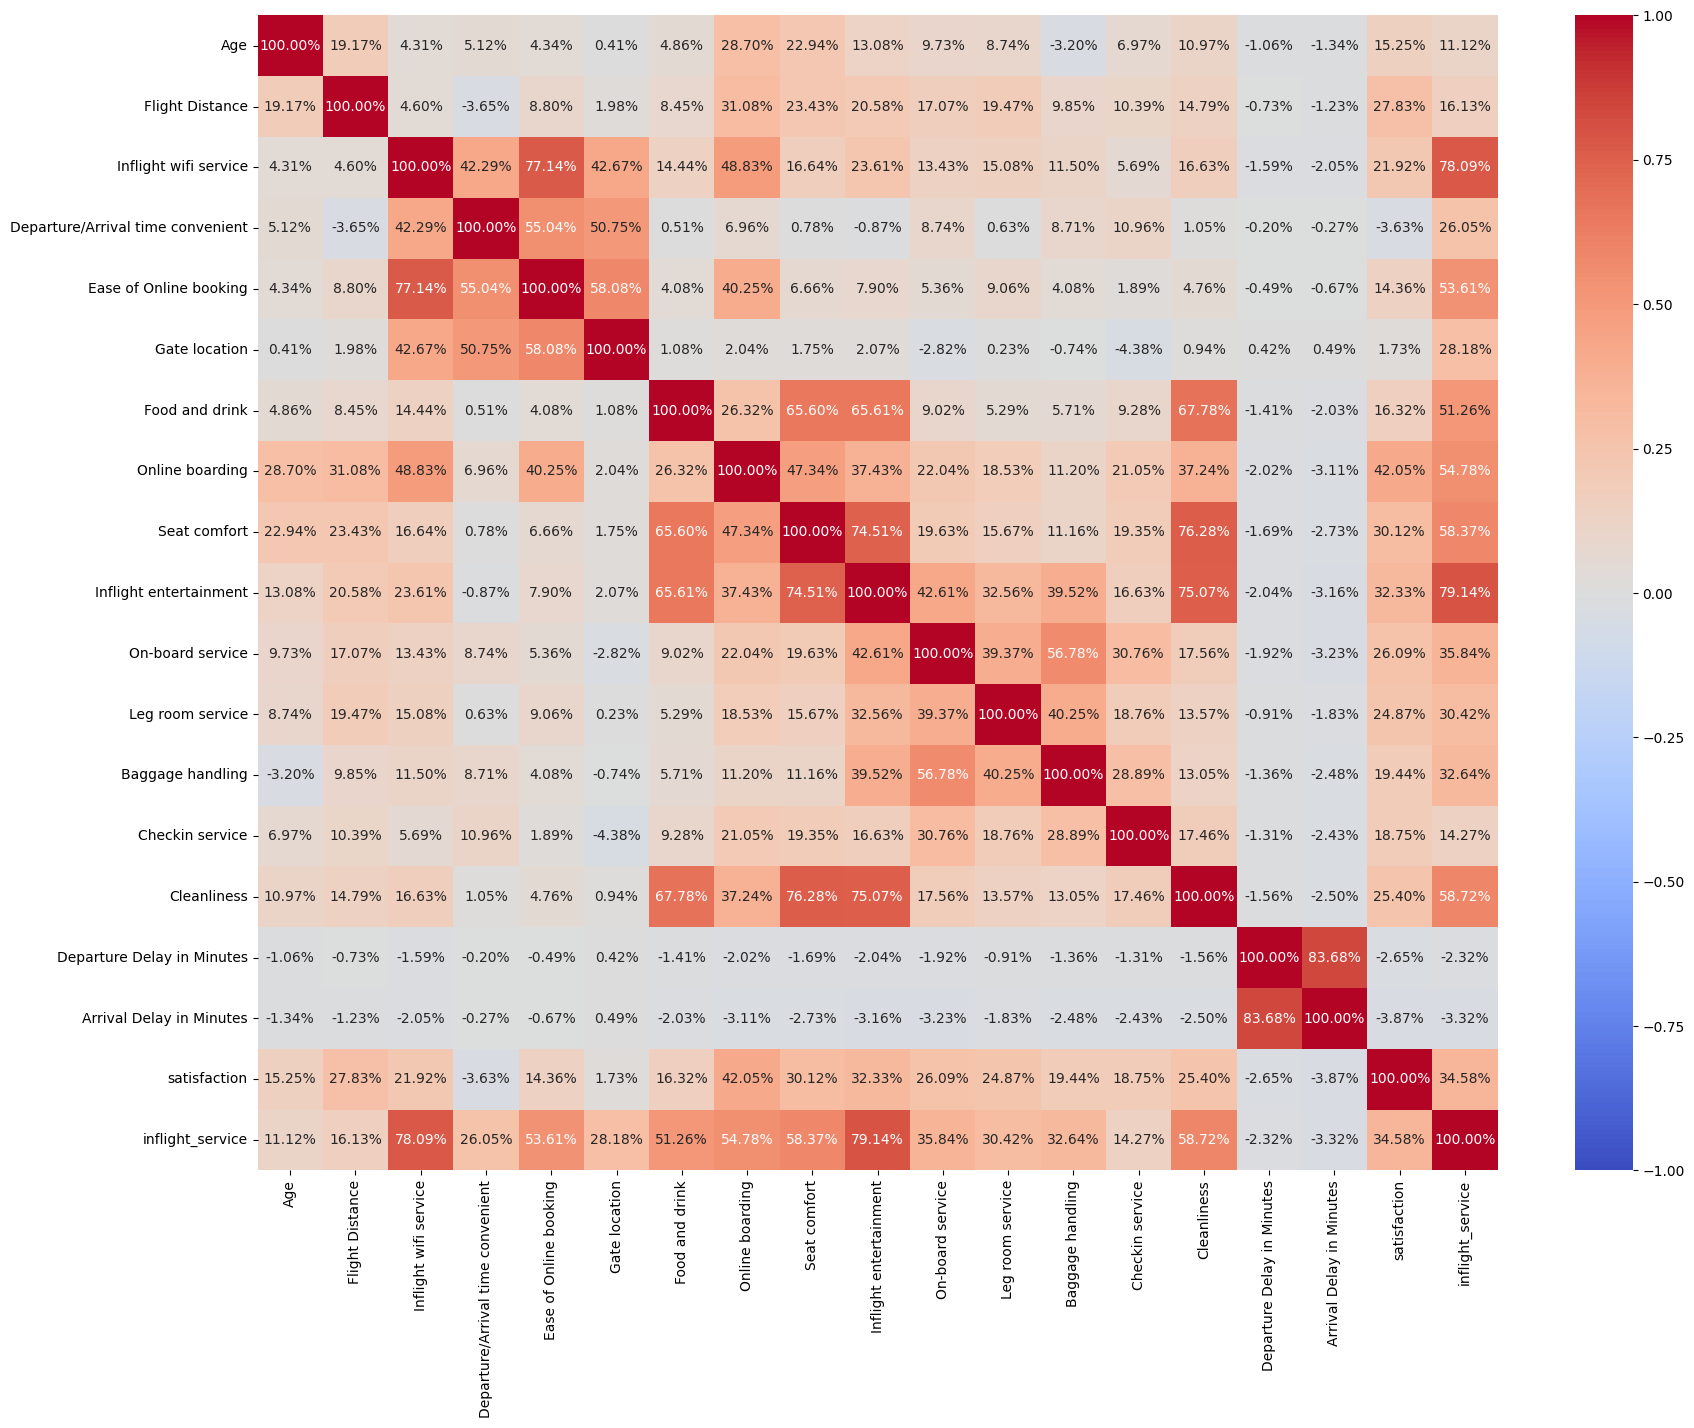

In [15]:
corr_mtx = df[features_numericas].corr()
plt.figure(figsize=(20,15))
sns.heatmap(
    corr_mtx,
    vmin=-1,
    vmax=1,
    cmap='coolwarm',
    annot=True,
    fmt='.2%'
)

In [16]:
df['Inflight wifi service'].describe()

count    999479.000000
mean          2.778081
std           1.280581
min           0.000000
25%           2.000000
50%           3.000000
75%           4.000000
max           5.000000
Name: Inflight wifi service, dtype: float64

In [17]:
df[features_numericas].corr()['satisfaction'].sort_values(ascending=False)

satisfaction                         1.000000
Online boarding                      0.420500
inflight_service                     0.345782
Inflight entertainment               0.323336
Seat comfort                         0.301239
Flight Distance                      0.278284
On-board service                     0.260929
Cleanliness                          0.253952
Leg room service                     0.248697
Inflight wifi service                0.219230
Baggage handling                     0.194382
Checkin service                      0.187533
Food and drink                       0.163206
Age                                  0.152535
Ease of Online booking               0.143567
Gate location                        0.017260
Departure Delay in Minutes          -0.026536
Departure/Arrival time convenient   -0.036344
Arrival Delay in Minutes            -0.038704
Name: satisfaction, dtype: float64

In [18]:
df[features_numericas].head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,inflight_service
0,36.0,694.0,4.0,4.0,4.0,3.0,1.0,4.0,1.0,1.0,3.0,4.0,4.0,3.0,1.0,0.0,0.0,0,2.5
1,56.0,651.0,5.0,5.0,5.0,5.0,5.0,4.0,4.0,5.0,5.0,5.0,5.0,4.0,3.0,0.0,0.0,1,5.0
2,31.0,1371.0,3.0,4.0,2.0,5.0,3.0,3.0,3.0,3.0,4.0,3.0,4.0,5.0,3.0,0.0,0.0,0,3.0
3,10.0,1616.0,3.0,5.0,3.0,3.0,3.0,3.0,3.0,3.0,4.0,5.0,3.0,4.0,3.0,0.0,0.0,0,3.0
4,23.0,481.0,3.0,4.0,3.0,4.0,5.0,3.0,5.0,5.0,5.0,4.0,5.0,3.0,5.0,5.0,0.0,0,4.0


In [19]:
for col in features_categoricas:
    print(f'{col} - {df[col].unique()}')

Gender - <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Customer Type - <StringArray>
['Loyal Customer', 'disloyal Customer']
Length: 2, dtype: str
Type of Travel - <StringArray>
['Personal Travel', 'Business travel']
Length: 2, dtype: str
Class - <StringArray>
['Eco', 'Business', 'Eco Plus']
Length: 3, dtype: str


In [20]:
# sns.relplot(
#     x=df['Flight Distance'], y=df['Departure Delay in Minutes'], hue=df['satisfaction'],data=df, height=6,
# );

In [21]:
# features = ['Flight Distance','Departure Delay in Minutes']

# kmeans = KMeans(n_clusters=3)
# df["Cluster"] = kmeans.fit_predict(df[features])
# df["Cluster"] = df["Cluster"].astype("category")

In [22]:
df.select_dtypes(include=['number']).columns

Index(['Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction', 'inflight_service'],
      dtype='str')

In [23]:
features_to_scaler = ['Inflight wifi service', 'Departure/Arrival time convenient',
    'Ease of Online booking', 'Gate location', 'Food and drink',
    'Online boarding', 'Seat comfort', 'Inflight entertainment',
    'On-board service', 'Leg room service', 'Baggage handling',
    'Checkin service', 'Cleanliness','Age', 'Flight Distance',
                      'Departure Delay in Minutes', 'Arrival Delay in Minutes']

features_to_one_hot = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

preprocessor = ColumnTransformer(
    transformers=[
        ('scaler', StandardScaler(), features_to_scaler),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
         features_to_one_hot),
    ],
    remainder='passthrough'
)

new_transform_data = preprocessor.fit_transform(df)
names = preprocessor.get_feature_names_out()

new_df = pd.DataFrame(data=new_transform_data, columns=names)
new_df.head()

,scaler__Inflight wifi service,scaler__Departure/Arrival time convenient,scaler__Ease of Online booking,scaler__Gate location,scaler__Food and drink,scaler__Online boarding,scaler__Seat comfort,scaler__Inflight entertainment,scaler__On-board service,scaler__Leg room service,...,cat__Gender_Male,cat__Customer Type_Loyal Customer,cat__Customer Type_disloyal Customer,cat__Type of Travel_Business travel,cat__Type of Travel_Personal Travel,cat__Class_Business,cat__Class_Eco,cat__Class_Eco Plus,remainder__satisfaction,remainder__inflight_service
0,0.954192,0.572949,0.892764,-0.010804,-1.743475,0.493289,-2.014964,-1.875776,-0.416380,0.415360,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,2.5
1,1.735088,1.250854,1.644905,1.583935,1.332846,0.493289,0.337225,1.181052,1.196942,1.201379,...,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,5.0
2,0.173295,0.572949,-0.611518,1.583935,-0.205314,-0.283081,-0.446838,-0.347362,0.390281,-0.370660,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,3.0
3,0.173295,1.250854,0.140623,-0.010804,-0.205314,-0.283081,-0.446838,-0.347362,0.390281,1.201379,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,3.0
4,0.173295,0.572949,0.140623,0.786565,1.332846,-0.283081,1.121287,1.181052,1.196942,0.415360,...,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,4.0


In [24]:
df_training = new_df[:len(df_train)]
df_testing = new_df[len(df_train):]

In [25]:
df_testing = df_testing.drop(columns=['remainder__satisfaction'])

In [26]:
X = df_training.drop(columns=['remainder__satisfaction'])
y = df_training['remainder__satisfaction']

X_train, X_temp, y_train, y_temp = train_test_split(X,y,test_size=0.3,shuffle=True, 
                                                    random_state=0, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,test_size=0.5,shuffle=True, 
                                                    random_state=0, stratify=y_temp)

print(X_train.shape, X_val.shape, X_test.shape)

(489744, 27) (104945, 27) (104946, 27)


In [27]:
sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train
)

In [28]:
# param_dist_lgb = {
#     'n_estimators': stats.randint(800, 1200),
#     'learning_rate': stats.uniform(0.01, 0.1),
#     'num_leaves': stats.randint(20, 64),       
#     'max_depth': stats.randint(6, 12), 
#     'subsample': stats.uniform(0.5, 0.5),
#     'subsample_freq': [1],                   
#     'colsample_bytree': stats.uniform(0.5, 0.5), 
#     'min_child_samples': stats.randint(10, 100),
#     'reg_alpha': stats.uniform(0, 3),
#     'reg_lambda': stats.uniform(0, 3)
# }

# lgbm_model = LGBMClassifier(verbose=-1)

# random_search = RandomizedSearchCV(
#     estimator=lgbm_model,
#     param_distributions=param_dist_lgb,
#     n_iter=10,
#     cv=5,
#     scoring='roc_auc',
#     verbose=2,
#     n_jobs=1
# )

# random_search.fit(
#     X_train, 
#     y_train,
#     sample_weight=sample_weights
# )

In [29]:
params ={'colsample_bytree': np.float64(0.517560050132764),
 'learning_rate': np.float64(0.04647413870156873),
 'max_depth': 9,
 'min_child_samples': 90,
 'n_estimators': 1176,
 'num_leaves': 50,
 'reg_alpha': np.float64(1.2074867614981746),
 'reg_lambda': np.float64(2.2529725211714715),
 'subsample': np.float64(0.8899457339247691),
 'subsample_freq': 1}


In [30]:
import lightgbm as lgb

lgbm = LGBMClassifier(**params, verbose=-1)
lgbm.fit(X_train, y_train,
         eval_set=[(X_val, y_val)],
         eval_metric='auc',
         sample_weight=sample_weights,
         callbacks=[lgb.early_stopping(50)])

/home/orlandojunior/miniconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[561]	valid_0's auc: 0.958408	valid_0's binary_logloss: 0.229224


,boosting_type,'gbdt'
,num_leaves,50
,max_depth,9
,learning_rate,np.float64(0....7413870156873)
,n_estimators,1176
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,90


In [31]:
y_pred = lgbm.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       0.93      0.94      0.93     58395
         1.0       0.92      0.91      0.92     46551

    accuracy                           0.93    104946
   macro avg       0.92      0.92      0.92    104946
weighted avg       0.93      0.93      0.93    104946



0.9586824978616728

In [32]:
y_pred_roc = lgbm.predict_proba(X_test)[:, 1]
print(roc_auc_score(y_test, y_pred_roc))

0.9586824978616728


<Axes: >

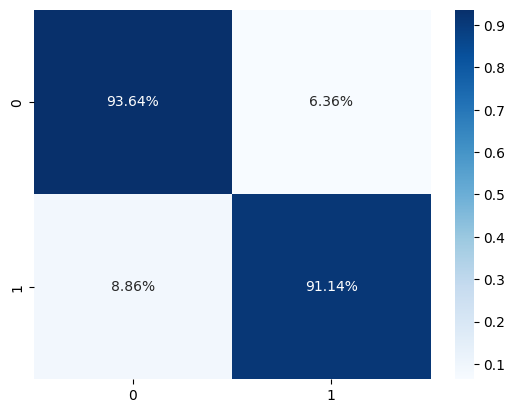

In [33]:
cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(
    cm,
    fmt='.2%',
    cmap='Blues',
    annot=True
)

In [34]:
pred_final = lgbm.predict_proba(df_testing)[:, 1]

df_final = pd.DataFrame({
    "id":ids,
    "satisfaction":pred_final
})

df_final.to_csv('submission.csv', index=False)